## 1. Setup

In [1]:
import os
import sys
from google.colab import drive
drive.mount("/content/drive")

REPO = "Arabic-sarcasm"

if not os.path.exists(f"/content/{REPO}"):
    !git clone https://github.com/cad0m/{REPO}.git /content/{REPO}
else:
    !git -C /content/{REPO} pull

%cd /content/{REPO}

if f"/content/{REPO}" not in sys.path:
    sys.path.insert(0, f"/content/{REPO}")

!pip install -q transformers arabert emoji tashaphyne nltk

Mounted at /content/drive
Cloning into '/content/Arabic-sarcasm'...
remote: Enumerating objects: 313, done.
remote: Counting objects: 100% (313/313), done.
remote: Compressing objects: 100% (223/223), done.
remote: Total 313 (delta 145), reused 214 (delta 69), pack-reused 0 (from 0)
Receiving objects: 100% (313/313), 3.66 MiB | 19.91 MiB/s, done.
Resolving deltas: 100% (145/145), done.
/content/Arabic-sarcasm
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


Results, predictions and checkpoints are written straight to Google Drive, so a disconnected session loses nothing.

In [2]:
import shutil
from pathlib import Path

ROOT = Path("/content/Arabic-sarcasm")
DRIVE = Path("/content/drive/MyDrive/sarcasm")

for name in ["results", "predictions", "models"]:
    local, remote = ROOT / name, DRIVE / name
    if not remote.exists():
        if local.exists():
            shutil.copytree(local, remote)
        else:
            remote.mkdir(parents=True)
    if local.exists() and not local.is_symlink():
        shutil.rmtree(local)
    if not local.exists():
        local.symlink_to(remote)

## 2. Data

In [3]:
import sys
sys.path.insert(0, "/content/Arabic-sarcasm")

import numpy as np
import pandas as pd
import torch
from transformers import AutoTokenizer

from src.data import get_data
from src.evaluate import RESULTS, log_result, metrics, plot_results, save_predictions, show
from src.fine_tune import DEVICE, PLMS, MultiTask, SingleTask, predict_proba, prepare_text, train_model
from src.train import best_threshold, count_params, set_seed

MODEL = "arabert"
PLM = PLMS[MODEL]
MAX_LEN = PLM["max_len"]
SEEDS = [42, 43, 44]
LAMS = [0.3, 0.5, 1.0]

train, val, test, report = get_data()
print(report)

{'start': 11293, 'key_exact/dup_train': 54, 'key_exact/dup_val': 0, 'key_exact/dup_test': 4, 'key_exact/train_in_test': 2, 'key_exact/test_in_train': 2, 'key/dup_train': 331, 'key/dup_val': 4, 'key/dup_test': 5, 'key/train_in_test': 2, 'key/test_in_train': 2, 'conflict_groups': 59, 'conflict_rows': 120, 'removed_in_test': 2, 'removed_in_val': 72, 'removed_conflicting': 96, 'removed_duplicates': 281, 'end': 10842}


Texts are prepared once for all runs. Check 5 tweets before and after, and how many tweets are cut by `max_len`.

In [4]:
tokenizer = AutoTokenizer.from_pretrained(PLM["hf_name"])

x_train = prepare_text(MODEL, train["tweet"])
x_val = prepare_text(MODEL, val["tweet"])
x_test = prepare_text(MODEL, test["tweet"])

y_train = train["sarcasm"].to_numpy()
s_train = train["sentiment_id"].to_numpy()
y_val = val["sarcasm"].to_numpy()
y_test = test["sarcasm"].to_numpy()

for before, after in zip(train["tweet"].head(5), x_train[:5]):
    print(before)
    print(after)
    print()

lengths = np.array([len(tokenizer(t)["input_ids"]) for t in x_train])
print("tweets longer than max_len:", (lengths > MAX_LEN).mean())

config.json:   0%|          | 0.00/667 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/476 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/751k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.25M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

"#لافروف: #موسكو تأمل بإجراء حوار بناء بشأن الأزمة في #سورية خلال لقائي مع وزيري خارجية #إيران و #تركيا غداً https://t.co/m2ejSZD6WP"
" # لافروف : # موسكو تأمل بإجراء حوار بناء بشأن الأزمة في # سورية خلال لقائي مع وزيري خارجية # إيران و # تركيا غدا [رابط] "

"RT @jalalyw: @EHSANFAKEEH تفصيل الخبر لمن يريدالإستزادة والإطلاع 10دورسينما ف مصرستعرض فيلماعن بطولات قاسم سليماني ف العراق وسوريامن إنتا…"
" RT [مستخدم] : [مستخدم] تفصيل الخبر لمن يريدالإستزادة والإطلاع 10 دورسينما ف مصرستعرض فيلماعن بطولات قاسم سليماني ف العراق وسوريامن إنتا … "

تحدثنا عن هذا الكتاب الجميل عن خروج المصريين على السلاطين في وقت كان الحديث فيه عن خنوع المصريين موضةهذا الجزء الأول
تحدثنا عن هذا الكتاب الجميل عن خروج المصريين على السلاطين في وقت كان الحديث فيه عن خنوع المصريين موضةهذا الجزء الأول

"RT @Jokes__99: بوكيمون ولحقتوه عيل المسيح الدجال عمياني بتتبعونه 😔😔😔😔"
" RT [مستخدم] : بوكيمون ولحقتوه عيل المسيح الدجال عمياني بتتبعونه 😔 😔 "

"أوباما يلاحق محمد بن سلمان !!: https://t.co/xDtS3uKFal via @YouTube"
" أوبام

## 3. What one run does

In [5]:
def make_model(task, lam):
    if task == "single":
        model = SingleTask(PLM["hf_name"])
    else:
        model = MultiTask(PLM["hf_name"], lam)
    return model.to(DEVICE)


def already_done(name, seed):
    if not RESULTS.exists() or RESULTS.stat().st_size == 0:
        return False
    table = pd.read_csv(RESULTS)
    same = (table["model"] == name) & (table["preprocessing"] == PLM["prep"]) & (table["seed"] == seed)
    return bool(same.any())

In [6]:
def run_one(task, lam, seed):
    name = f"{MODEL}_{task}_lam{lam}"
    if already_done(name, seed):
        print("already done:", name, "seed", seed)
        return

    # 1. train (the model is left at its best epoch)
    set_seed(seed)
    model = make_model(task, lam)
    train_time = train_model(model, tokenizer, x_train, y_train, s_train, x_val, y_val, MAX_LEN)

    # 2. validation: choose the threshold
    val_proba = predict_proba(model, tokenizer, x_val, MAX_LEN)
    threshold = best_threshold(y_val, val_proba)
    val_scores = metrics(y_val, val_proba, threshold)

    # 3. test: use the validation threshold
    test_proba = predict_proba(model, tokenizer, x_test, MAX_LEN)
    test_scores = metrics(y_test, test_proba, threshold)
    save_predictions(name, seed, test["id"], y_test, test_proba, threshold)

    # 4. log
    row = {"model": name, "preprocessing": PLM["prep"], "seed": seed, "lam": lam,
           "threshold": threshold, "train_time": train_time, "trained_params": count_params(model)}
    row.update({"val_" + k: v for k, v in val_scores.items()})
    row.update({"test_" + k: v for k, v in test_scores.items()})
    log_result(**row)
    show(name, val_scores, threshold, train_time)

    # 5. checkpoint, first seed only
    if seed == SEEDS[0]:
        torch.save({"state_dict": {k: v.cpu() for k, v in model.state_dict().items()},
                    "hf_name": PLM["hf_name"], "task": task, "lam": lam, "prep": PLM["prep"],
                    "max_len": MAX_LEN, "threshold": threshold},
                   ROOT / "models" / f"{name}_seed{seed}.pt")

    torch.cuda.empty_cache()

# single head with seeds: 42, 43, 44.


In [7]:
run_one("single", 0, SEEDS[0]) #42

already done: arabert_single_lam0 seed 42


In [14]:
run_one("single", 0, SEEDS[1]) #43

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: aubmindlab/bert-base-arabertv02-twitter
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


epoch 1: val f1 = 0.6939
epoch 2: val f1 = 0.6825
epoch 3: val f1 = 0.6871
arabert_single_lam0          f1=0.6939  pr_auc=0.7252  threshold=0.73  120s


In [8]:
run_one("single", 0, SEEDS[2]) #44

model.safetensors: reconstructing file:   0%|          |  0.00B /  541MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: aubmindlab/bert-base-arabertv02-twitter
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


epoch 1:   0%|          | 0/339 [00:00<?, ?it/s]

...

epoch 2: val f1 = 0.6986


epoch 3:   0%|          | 0/339 [00:00<?, ?it/s]

epoch 3: val f1 = 0.6935


epoch 4:   0%|          | 0/339 [00:00<?, ?it/s]

epoch 4: val f1 = 0.7028
arabert_single_lam0          f1=0.7028  pr_auc=0.7088  threshold=0.64  195s


# run Multi-task with seed 42 and different lambda

In [9]:
run_one("multi", LAMS[0], SEEDS[0]) # seed 0 lam 0.3

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: aubmindlab/bert-base-arabertv02-twitter
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


epoch 1:   0%|          | 0/339 [00:00<?, ?it/s]

/content/Arabic-sarcasm/src/fine_tune.py:134: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


epoch 1: val f1 = 0.6864


epoch 2:   0%|          | 0/339 [00:00<?, ?it/s]

epoch 2: val f1 = 0.6767


epoch 3:   0%|          | 0/339 [00:00<?, ?it/s]

epoch 3: val f1 = 0.6843
arabert_multi_lam0.3         f1=0.6864  pr_auc=0.7130  threshold=0.54  148s


In [10]:
run_one("multi", LAMS[1], SEEDS[0]) # seed 42 lam 0.5

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: aubmindlab/bert-base-arabertv02-twitter
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


epoch 1:   0%|          | 0/339 [00:00<?, ?it/s]

/content/Arabic-sarcasm/src/fine_tune.py:134: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


epoch 1: val f1 = 0.6886


epoch 2:   0%|          | 0/339 [00:00<?, ?it/s]

epoch 2: val f1 = 0.6791


epoch 3:   0%|          | 0/339 [00:00<?, ?it/s]

epoch 3: val f1 = 0.6882
arabert_multi_lam0.5         f1=0.6886  pr_auc=0.7160  threshold=0.57  123s


In [11]:
run_one("multi", LAMS[2], SEEDS[0]) # seed 42 lam 1.0

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: aubmindlab/bert-base-arabertv02-twitter
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


epoch 1:   0%|          | 0/339 [00:00<?, ?it/s]

/content/Arabic-sarcasm/src/fine_tune.py:134: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


epoch 1: val f1 = 0.6964


epoch 2:   0%|          | 0/339 [00:00<?, ?it/s]

epoch 2: val f1 = 0.6860


epoch 3:   0%|          | 0/339 [00:00<?, ?it/s]

epoch 3: val f1 = 0.6893
arabert_multi_lam1.0         f1=0.6964  pr_auc=0.7187  threshold=0.53  123s


# run Multi-task with seed 43 and different lambda

In [12]:
run_one("multi", LAMS[0], SEEDS[1]) # seed 43 lam 0.3

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: aubmindlab/bert-base-arabertv02-twitter
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


epoch 1:   0%|          | 0/339 [00:00<?, ?it/s]

epoch 1: val f1 = 0.6988


epoch 2:   0%|          | 0/339 [00:00<?, ?it/s]

epoch 2: val f1 = 0.6941


epoch 3:   0%|          | 0/339 [00:00<?, ?it/s]

epoch 3: val f1 = 0.6958
arabert_multi_lam0.3         f1=0.6988  pr_auc=0.7245  threshold=0.66  123s


In [13]:
run_one("multi", LAMS[1], SEEDS[1]) # seed 43 lam 0.5

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: aubmindlab/bert-base-arabertv02-twitter
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


epoch 1:   0%|          | 0/339 [00:00<?, ?it/s]

epoch 1: val f1 = 0.6987


epoch 2:   0%|          | 0/339 [00:00<?, ?it/s]

epoch 2: val f1 = 0.6929


epoch 3:   0%|          | 0/339 [00:00<?, ?it/s]

epoch 3: val f1 = 0.6957
arabert_multi_lam0.5         f1=0.6987  pr_auc=0.7256  threshold=0.71  122s


In [14]:
run_one("multi", LAMS[2], SEEDS[1]) # seed 43 lam 1.0

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: aubmindlab/bert-base-arabertv02-twitter
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


epoch 1:   0%|          | 0/339 [00:00<?, ?it/s]

epoch 1: val f1 = 0.7028


epoch 2:   0%|          | 0/339 [00:00<?, ?it/s]

epoch 2: val f1 = 0.6931


epoch 3:   0%|          | 0/339 [00:00<?, ?it/s]

epoch 3: val f1 = 0.6986
arabert_multi_lam1.0         f1=0.7028  pr_auc=0.7237  threshold=0.65  122s


# run Multi-task with seed 44 and different lambda

In [15]:
run_one("multi", LAMS[0], SEEDS[2]) # seed 44 lam 0.3

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: aubmindlab/bert-base-arabertv02-twitter
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


epoch 1:   0%|          | 0/339 [00:00<?, ?it/s]

/content/Arabic-sarcasm/src/fine_tune.py:134: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


epoch 1: val f1 = 0.6822


...

epoch 2: val f1 = 0.6904


epoch 3:   0%|          | 0/339 [00:00<?, ?it/s]

epoch 3: val f1 = 0.6965


epoch 4:   0%|          | 0/339 [00:00<?, ?it/s]

epoch 4: val f1 = 0.6933
arabert_multi_lam0.3         f1=0.6965  pr_auc=0.7148  threshold=0.51  164s


In [16]:
run_one("multi", LAMS[1], SEEDS[2]) # seed 44 lam 0.5

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: aubmindlab/bert-base-arabertv02-twitter
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


epoch 1:   0%|          | 0/339 [00:00<?, ?it/s]

/content/Arabic-sarcasm/src/fine_tune.py:134: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


epoch 1: val f1 = 0.6808


...

epoch 2: val f1 = 0.6983


epoch 3:   0%|          | 0/339 [00:00<?, ?it/s]

epoch 3: val f1 = 0.6902


epoch 4:   0%|          | 0/339 [00:00<?, ?it/s]

epoch 4: val f1 = 0.6933
arabert_multi_lam0.5         f1=0.6983  pr_auc=0.7219  threshold=0.74  163s


In [17]:
run_one("multi", LAMS[2], SEEDS[2]) # seed 44 lam 1.0

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: aubmindlab/bert-base-arabertv02-twitter
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


epoch 1:   0%|          | 0/339 [00:00<?, ?it/s]

/content/Arabic-sarcasm/src/fine_tune.py:134: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


epoch 1: val f1 = 0.6710


...

epoch 2: val f1 = 0.6885


epoch 3:   0%|          | 0/339 [00:00<?, ?it/s]

epoch 3: val f1 = 0.6893


epoch 4:   0%|          | 0/339 [00:00<?, ?it/s]

epoch 4: val f1 = 0.6970
arabert_multi_lam1.0         f1=0.6970  pr_auc=0.7193  threshold=0.66  164s


## 5. Results
Validation F1 of the sarcastic class, mean and std over the 3 seeds (`count` must be 3 for every row).

In [18]:
results = pd.read_csv(RESULTS)
results = results[(results["preprocessing"] == PLM["prep"]) & results["model"].str.contains("_single_|_multi_")]

val_table = results.groupby("model")["val_f1"].agg(["mean", "std", "count"])
val_table

,mean,std,count
model,,,
arabert_multi_lam0.3,0.693925,0.006579,3
arabert_multi_lam0.5,0.695187,0.005712,3
arabert_multi_lam1.0,0.698715,0.003568,3
arabert_single_lam0,0.691036,0.013433,3


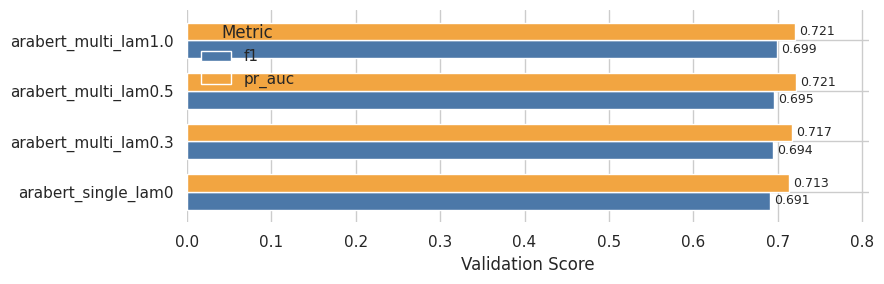

In [19]:
plot_table = results.groupby("model")[["val_f1", "val_pr_auc"]].mean()
plot_table.columns = ["f1", "pr_auc"]
plot_results(plot_table)

λ is chosen from the validation table. Test is shown only for E1 and the chosen E2.

In [20]:
multi = val_table[val_table.index.str.contains("_multi_")]
best_e2 = multi["mean"].idxmax()
print("chosen E2:", best_e2)

chosen = [f"{MODEL}_single_lam0", best_e2]
results[results["model"].isin(chosen)].groupby("model")["test_f1"].agg(["mean", "std"])

chosen E2: arabert_multi_lam1.0


,mean,std
model,,
arabert_multi_lam1.0,0.617209,0.014749
arabert_single_lam0,0.609056,0.022754
